# 横磁場イジングモデル（2. Jordan-Wigner変換）

モデルの定義・今回のゴール・1.厳密対角化は [01_exact_diag.ipynb](01_exact_diag.ipynb) を参照。

In [1]:
# 前の章で定義した関数は、共通パッケージ qmb から読み込む（src/qmb/ を参照）
import numpy as np
import matplotlib.pyplot as plt
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qmb.ed import ground_state, time_evolve_expectation
from qmb.operators import plus_state

## 2. Jordan-Wigner変換を用いてフェルミオンの問題に置き換える方法

### 2-1 Jordan-Wigner変換

各サイトのある2状態を「フェルミオンがいない/いる」の2状態とみなす。今回は$X_j$が対角になるように

- $\ket{+}$ : フェルミオンがいない（$n_j=0$）
- $\ket{-}$ : フェルミオンがいる（$n_j=1$）

と対応させる。このとき、初期状態$\ket{+\cdots+}$が**フェルミオンの真空**$\ket{0}$になる。

> #### フェルミオンとは
> 

ここで、あるサイトの「フェルミオンを1個消す/作る」演算子を考える。まず思いつくのは

- 消滅演算子：$a = \ket{+}\bra{-}$
- 生成演算子：$a^{\dagger} = \ket{-}\bra{+}$

のような演算子である。これはそれぞれの状態に作用させることで確かめられる。これは$a^2=(a^{\dagger})^2=0$よりパウリの排他原理も満たす。しかし,
別のサイトへの演算子同士の関係を考えた際に$[a_i, a_j]=0$と可換であり、フェルミオンの半可換な性質と反する。

> フェルミオンは演算子をかける順序を逆にすると「ー」が出る、すなわち半交換関係にある。
> - $c_i c_j\ket{\cdots -_i\cdots-_k\cdots} = \ket{\cdots +_i\cdots+_k\cdots}$
> - $c_j c_i\ket{\cdots -_i\cdots-_k\cdots} = -\ket{\cdots +_i\cdots+_k\cdots}$
>
> $\Rightarrow c_i c_j = -c_j c_i \iff \{c_i, c_j\}=0$

そこで以下のような演算子を考える。

\begin{equation}
c_j = \left(\prod_{k<j} X_k\right) a_j
\end{equation}

この演算子は、生成・消滅演算子として性質を保ち

- \{c_i, c_j\}=0

と反交換関係も満たす。これが**Jordan-Wigner変換**である。逆に解くと

\begin{equation}
X_j = 1 - 2c_j^\dagger c_j,\quad Z_j = \left(\prod_{k<j} X_k\right)(c_j + c_j^\dagger)
\end{equation}

とかける。

### 2-2 ハミルトニアンをフェルミオンで書く

それぞれ代入する。

- **横磁場の項**

  そのまま代入して

  \begin{equation}
  -h\sum_j X_j = -h\sum_j\left(1 - 2c_j^\dagger c_j\right)
  \end{equation}

- **イジング相互作用の項**

  $X_k^2 = 1$なので、隣り合うサイトではひもがほぼ打ち消し合い、$X_j$が1個だけ残る。

  \begin{equation}
  Z_j Z_{j+1} = (c_j + c_j^\dagger)\,X_j\,(c_{j+1} + c_{j+1}^\dagger)
  \end{equation}

  ここで$c_j c_j^\dagger c_j = c_j,\ c_j^\dagger c_j^\dagger c_j = 0$を使うと

  \begin{equation}
  (c_j + c_j^\dagger)X_j = (c_j + c_j^\dagger)(1 - 2c_j^\dagger c_j) = c_j^\dagger - c_j
  \end{equation}

  なので

  \begin{equation}
  \begin{aligned}
  Z_j Z_{j+1}
  &= (c_j^\dagger - c_j)(c_{j+1} + c_{j+1}^\dagger) \\
  &= c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j + c_j^\dagger c_{j+1}^\dagger + c_{j+1} c_j
  \end{aligned}
  \end{equation}

以上より、開放境界条件のハミルトニアンは

\begin{equation}
H = -J\sum_{j=1}^{n-1}\left(c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j + c_j^\dagger c_{j+1}^\dagger + c_{j+1} c_j\right) - h\sum_{j=1}^{n}\left(1 - 2c_j^\dagger c_j\right)
\end{equation}

となる。第1項の前半は隣のサイトへの**ホッピング**、後半は**ペアの生成・消滅**を表す。フェルミオンの数は保存しないが、ペアでしか増減しないので偶奇（パリティ）は保存する。

重要なのは、$H$が**フェルミオン演算子の2次形式**になっていることである。2次形式は相互作用のない自由粒子と同じで、$n$個の1粒子モードに分解して厳密に解ける。

> **周期境界条件の場合**
>
> 境界の項$Z_n Z_1$では左右のひもが打ち消し合わず、全パリティ$P = \prod_k X_k$が残る。そのためパリティごとにフェルミオンの境界条件が（反）周期的に変わる。基底状態は$P=+1$（反周期）の側にあり、波数$k = \pm\frac{\pi}{n}, \pm\frac{3\pi}{n}, \cdots$についてフーリエ変換すると
>
> \begin{equation}
> \varepsilon_k = 2\sqrt{J^2 + h^2 - 2Jh\cos k},\quad E_0 = -\frac{1}{2}\sum_k \varepsilon_k
> \end{equation}
>
> となる。$k\to 0$で$\varepsilon_k\to 2|J-h|$なので、$h=J$でギャップが閉じる（量子相転移）。以下では1-4と同じく開放境界条件で計算する。

### 2-3 基底エネルギー$E_0$

2次形式を行列で扱うため、生成・消滅演算子を並べた$2n$成分のベクトル（Nambu表示）

\begin{equation}
\Psi = (c_1, \cdots, c_n, c_1^\dagger, \cdots, c_n^\dagger)^T
\end{equation}

を導入する。$\sum_{ij} c_i^\dagger A_{ij} c_j = \frac{1}{2}\left(c^\dagger A c - c^T A c^\dagger\right) + \frac{1}{2}\mathrm{tr}A$と書き直すと、

\begin{equation}
H = \frac{1}{2}\Psi^\dagger H_{\mathrm{BdG}}\Psi,\quad
H_{\mathrm{BdG}} = \begin{pmatrix} A & B \\ -B & -A \end{pmatrix}
\end{equation}

となる（BdGはBogoliubov-de Gennesの略）。ここで$n\times n$行列$A, B$の成分は

\begin{equation}
A_{jj} = 2h,\quad A_{j,j+1} = A_{j+1,j} = -J,\quad B_{j,j+1} = -J,\quad B_{j+1,j} = +J
\end{equation}

で、それ以外は0である。定数項は$\frac{1}{2}\mathrm{tr}A - hn = hn - hn = 0$で打ち消し合う。

$H_{\mathrm{BdG}}$の固有値は必ず$\pm\varepsilon_k\ (\varepsilon_k\ge 0,\ k=1,\cdots,n)$の対で現れる（粒子と正孔の入れ替えで符号が反転するため）。$H_{\mathrm{BdG}}$を対角化するユニタリ行列で$\Psi$を変換した新しいフェルミオン$\eta_k$（**Bogoliubov変換**）を使うと

\begin{equation}
H = \sum_{k=1}^{n}\varepsilon_k\left(\eta_k^\dagger\eta_k - \frac{1}{2}\right)
\end{equation}

となる。$\varepsilon_k\ge0$なので、どの$\eta_k$も占有しない状態が基底状態であり

\begin{equation}
E_0 = -\frac{1}{2}\sum_{k=1}^{n}\varepsilon_k
\end{equation}

である。励起状態は$E_0$に$\varepsilon_k$をいくつか足したものになる。

厳密対角化では$2^n\times 2^n$行列が必要だったが、ここでは**$2n\times 2n$行列**の対角化だけで済む。

### 2-4 横磁化$m_x(t)$

$X_j = 1 - 2c_j^\dagger c_j$より

\begin{equation}
M_x = \frac{1}{n}\sum_{j=1}^{n} X_j = 1 - \frac{2}{n}\sum_{j=1}^{n} c_j^\dagger c_j
\end{equation}

なので、各サイトの粒子数$\langle c_j^\dagger c_j\rangle$の時間発展がわかればよい。

ここではHeisenberg描像$\Psi(t) = e^{iHt}\Psi e^{-iHt}$で考える。交換関係を計算すると$[H, \Psi] = -H_{\mathrm{BdG}}\Psi$となるので、

\begin{equation}
\frac{d}{dt}\Psi(t) = i[H, \Psi(t)] = -iH_{\mathrm{BdG}}\Psi(t)
\Rightarrow \Psi(t) = U(t)\Psi,\quad U(t) = e^{-iH_{\mathrm{BdG}}t}
\end{equation}

つまり演算子の時間発展は$2n\times2n$行列$U(t)$を掛けるだけで求まる。$U(t)$を$n\times n$のブロックに分けて

\begin{equation}
U(t) = \begin{pmatrix} U_{11} & U_{12} \\ U_{21} & U_{22} \end{pmatrix}
\Rightarrow
c_j(t) = \sum_k\left[(U_{11})_{jk}c_k + (U_{12})_{jk}c_k^\dagger\right]
\end{equation}

初期状態$\ket{+\cdots+}$はフェルミオンの真空$\ket{0}$なので、$c_k\ket{0}=0$より$c_k c_k^\dagger$の項だけが残り

\begin{equation}
\bra{0}c_j^\dagger(t)c_j(t)\ket{0} = \sum_k\left|(U_{12})_{jk}\right|^2
\end{equation}

これらより横磁化$m_x(t)$は

\begin{equation}
m_x(t) = 1 - \frac{2}{n}\sum_{j,k}\left|\left(U_{12}(t)\right)_{jk}\right|^2
\end{equation}

である。$U_{12}$は「真空から粒子のペアがどれだけ生まれたか」を表しており、$t=0$では$U_{12}=0$なので$m_x(0)=1$となる。

### 2-5 具体例を考えてみる

1-3と同じく$n=2$（開放境界）の場合を手で計算する。

- **基底エネルギー$E_0$**

  2-3の定義より

  $$
  A = \begin{pmatrix} 2h & -J \\ -J & 2h \end{pmatrix},\quad
  B = \begin{pmatrix} 0 & -J \\ J & 0 \end{pmatrix}
  $$

  $H_{\mathrm{BdG}}$の固有値を求めるのに次の工夫を使う。$Q = \frac{1}{\sqrt{2}}\begin{pmatrix} I & I \\ I & -I\end{pmatrix}$で基底を変えると

  $$
  QH_{\mathrm{BdG}}Q = \begin{pmatrix} 0 & A-B \\ A+B & 0 \end{pmatrix}
  \Rightarrow
  (QH_{\mathrm{BdG}}Q)^2 = \begin{pmatrix} (A-B)(A+B) & 0 \\ 0 & (A+B)(A-B) \end{pmatrix}
  $$

  なので、$\varepsilon_k^2$は$(A-B)(A+B)$の固有値である。実際に計算すると

  $$
  (A-B)(A+B)
  = \begin{pmatrix} 2h & 0 \\ -2J & 2h \end{pmatrix}\begin{pmatrix} 2h & -2J \\ 0 & 2h \end{pmatrix}
  = \begin{pmatrix} 4h^2 & -4hJ \\ -4hJ & 4J^2+4h^2 \end{pmatrix}
  $$

  トレースが$4J^2+8h^2$、行列式が$16h^4$なので、固有値は

  $$
  \lambda = 2J^2 + 4h^2 \pm 2J\sqrt{J^2+4h^2} = \left(\sqrt{J^2+4h^2} \pm J\right)^2
  $$

  よって1粒子エネルギーは

  $$
  \varepsilon_\pm = \sqrt{J^2+4h^2} \pm J
  $$

  であり、基底エネルギーは

  $$
  E_0 = -\frac{1}{2}(\varepsilon_+ + \varepsilon_-) = -\sqrt{J^2+4h^2}
  $$

  となり、1-3の結果と一致する。さらに励起状態も

  $$
  E_0 + \varepsilon_- = -J,\quad E_0 + \varepsilon_+ = J,\quad E_0 + \varepsilon_+ + \varepsilon_- = \sqrt{J^2+4h^2}
  $$

  となり、1-3で求めた4つの固有値がすべて再現される。$2^2=4$個の多体の固有値が、たった2個の1粒子エネルギー$\varepsilon_\pm$の組み合わせで表されていることがわかる。

- **横磁化$m_x(t)$**

  $J=1, h=0.5$では$\varepsilon_\pm = \sqrt{2}\pm1$である。$m_x(t)$は2-4の式で数値的に計算し、1-3の結果$\cos^2(\sqrt{2}t)$と比較する。

### 2-6 コードで確かめる

2-3, 2-4の式をpythonで実装する。

1粒子エネルギー ε = [0.41421356 2.41421356]  (手計算: √2-1 = 0.414214, √2+1 = 2.414214)
基底エネルギー E0 (JW)   = -1.414214
基底エネルギー E0 (厳密対角化) = -1.414214


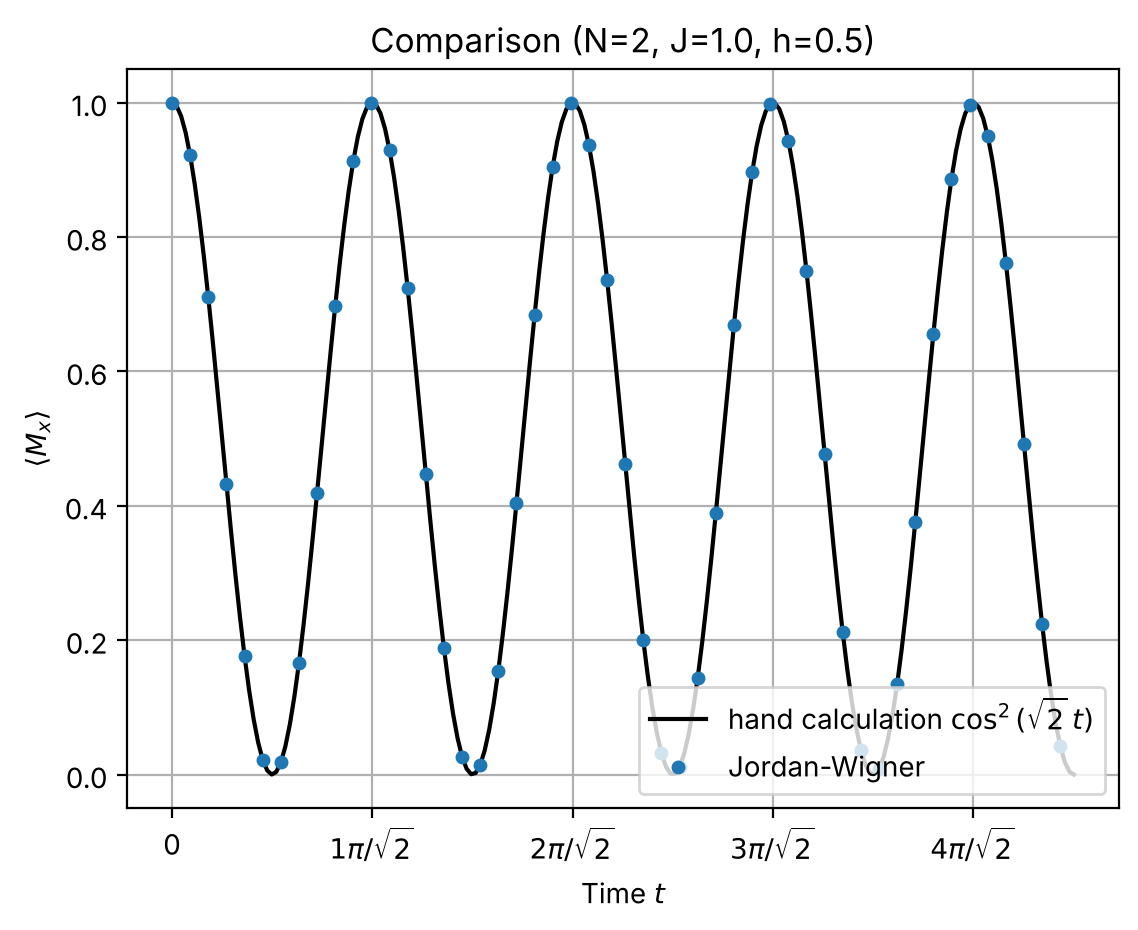

In [2]:
# BdG行列 H_BdG = [[A, B], [-B, -A]]（開放境界）
def bdg_matrix(n, J, h):
    A = np.zeros((n, n))
    B = np.zeros((n, n))
    for j in range(n):
        A[j, j] = 2 * h               # 横磁場 → 化学ポテンシャル
    for j in range(n - 1):
        A[j, j + 1] = A[j + 1, j] = -J  # ホッピング
        B[j, j + 1] = -J                 # ペア生成・消滅
        B[j + 1, j] = J
    return np.block([[A, B], [-B, -A]])

# 1粒子エネルギー ε_k（H_BdGの正の固有値）
def quasiparticle_energies(n, J, h):
    e = np.linalg.eigvalsh(bdg_matrix(n, J, h))
    return e[n:]   # 固有値は ±ε_k の対なので後半の n 個が ε_k

# 基底エネルギー E0 = -(1/2) Σ ε_k
def ground_energy_jw(n, J, h):
    return -0.5 * np.sum(quasiparticle_energies(n, J, h))

# 横磁化 m_x(t) = 1 - (2/n) Σ |U12|^2
def mx_jw(n, J, h, ts):
    """1. H_BdG = W D W† と対角化（1回だけ）
    2. U(t) = W e^{-iDt} W†
    3. 右上ブロック U12 から m_x(t) を計算
    """
    w, W = np.linalg.eigh(bdg_matrix(n, J, h))
    out = []
    for t in ts:
        U = (W * np.exp(-1j * w * t)) @ W.conj().T
        U12 = U[:n, n:]
        out.append(1 - 2 / n * np.sum(np.abs(U12)**2))
    return np.array(out)

# 例: N=2, J=1, h=0.5（1-4と同じ条件）
N = 2
J = 1.0
h = 0.5

eps = quasiparticle_energies(N, J, h)
E0_jw = ground_energy_jw(N, J, h)
print(f"1粒子エネルギー ε = {eps}  (手計算: √2-1 = {np.sqrt(2)-1:.6f}, √2+1 = {np.sqrt(2)+1:.6f})")
print(f"基底エネルギー E0 (JW)   = {E0_jw:.6f}")
print(f"基底エネルギー E0 (厳密対角化) = {ground_state(hamiltonian(N, J, h, pbc=False))[0]:.6f}")

ts = np.linspace(0, 10, 200)
mx = mx_jw(N, J, h, ts)

T = np.pi / np.sqrt(2)   # 周期
plt.plot(ts, np.cos(np.sqrt(2) * ts)**2, "k-", label=r"hand calculation $\cos^2(\sqrt{2}\,t)$")
plt.plot(ts[::4], mx[::4], "o", ms=4, label="Jordan-Wigner")
plt.xticks([k * T for k in range(5)], ["0"] + [rf"${k}\pi/\sqrt{{2}}$" for k in range(1, 5)])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend(loc="lower right")
plt.grid()
plt.show()

$n=2$では手計算と一致した。次に$n=10$で1.厳密対角化（$2^{10}\times2^{10}=1024\times1024$行列）と2.JW変換（$20\times20$行列）を比較する。

E0 (厳密対角化) = -10.5458443704
E0 (JW)         = -10.5458443704


m_x(t) の最大誤差 = 3.33e-15


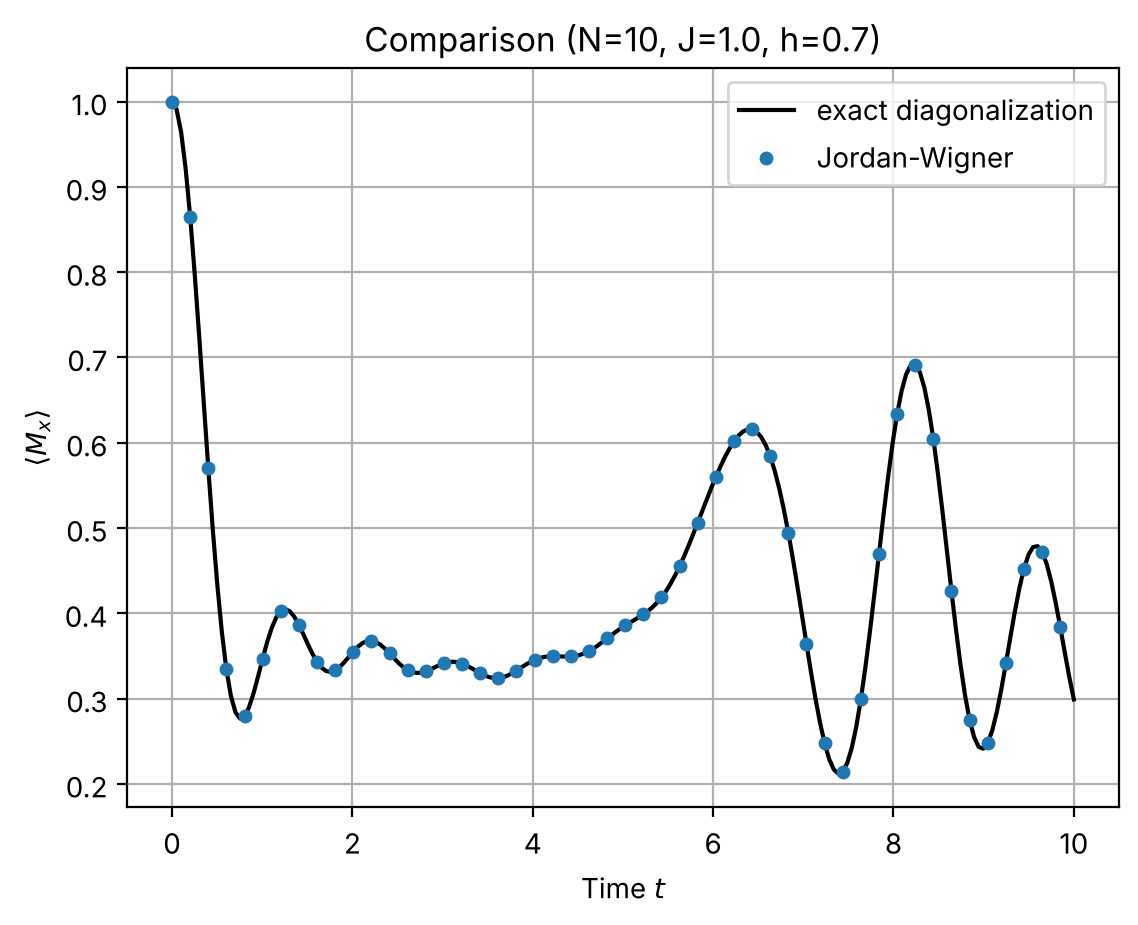

In [3]:
N = 10
J = 1.0
h = 0.7
ts = np.linspace(0, 10, 200)

H = hamiltonian(N, J, h, pbc=False)
E0_ed = ground_state(H)[0]
E0_jw = ground_energy_jw(N, J, h)
print(f"E0 (厳密対角化) = {E0_ed:.10f}")
print(f"E0 (JW)         = {E0_jw:.10f}")

mx_ed = time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts)
mx_f = mx_jw(N, J, h, ts)
print(f"m_x(t) の最大誤差 = {np.max(np.abs(mx_ed - mx_f)):.2e}")

plt.plot(ts, mx_ed, "k-", label="exact diagonalization")
plt.plot(ts[::4], mx_f[::4], "o", ms=4, label="Jordan-Wigner")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend()
plt.grid()
plt.show()

このようにJordan-Wigner変換を使うと、横磁場イジングモデルは自由フェルミオンの問題になり、計算コストが$2^n$から$n^3$程度まで下がる。ただしこれは$H$がフェルミオンの2次形式になるという**このモデル特有の性質**によるもので、例えば縦磁場$\sum_j Z_j$を加えると2次形式でなくなり、この方法は使えない。そのような一般の場合にも使える方法が次の量子回路による方法である。

---
**前へ**: [1. 厳密対角化](01_exact_diag.ipynb)　｜　**次へ**: [3. 量子回路で解く方法](03_quantum_circuit.ipynb)